<a href="https://colab.research.google.com/github/juuaann09/Metodos/blob/main/Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Método de Newton

###Ejemplo 1 de la página 51 de Burden.
Se requiere encontrar una raíz de la función trigonométrica:
$$f(x) = \cos(x) - x = 0$$

Sabemos que existe un solo punto fijo en el intervalo $[0, \pi/2]$. Observe que la variable en la función trigonométrica está medida en radianes, no en grados.

Para aplicar el método de Newton, necesitamos calcular la derivada de la función $f(x)$. Derivando obtenemos:
$$f'(x) = -\sin(x) - 1$$

Iniciaremos la búsqueda de la raíz con un valor inicial $p_0 = \pi/4$.

In [29]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    # np.cos() asume que el ángulo de entrada 'x' está en radianes
    return np.cos(x) - x

def df(x):
    # np.sin() también trabaja en radianes
    return -np.sin(x) - 1

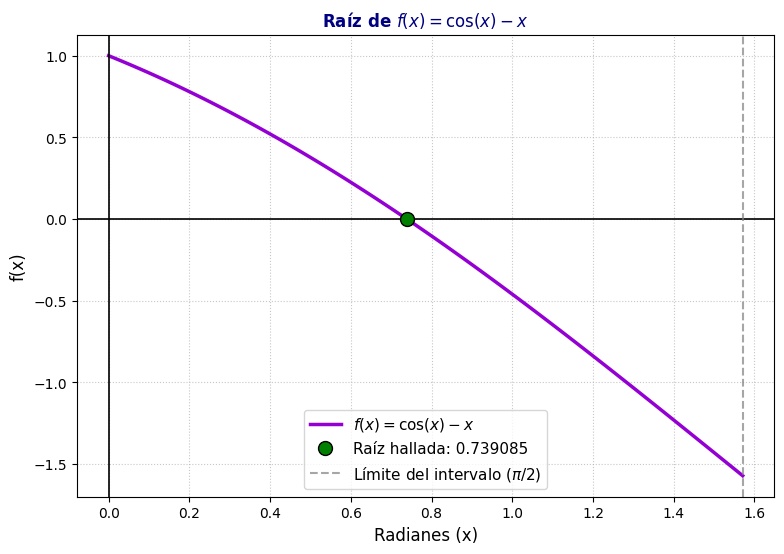

In [33]:
# Generamos 100 puntos espaciados uniformemente entre 0 y pi/2
xx = np.linspace(0, np.pi/2, 100)

plt.figure(figsize=(9, 6))

# Agregamos la 'r' antes de las comillas en el label
plt.plot(xx, f(xx), label=r'$f(x) = \cos(x) - x$', color='darkviolet', linewidth=2.5)

plt.axhline(y=0, color='black', linewidth=1.2)
plt.axvline(x=0, color='black', linewidth=1.2)

plt.plot(raiz_final, 0, 'go', markersize=10, markeredgecolor='black',
         label=f'Raíz hallada: {raiz_final:.6f}')

# Agregamos la 'r' antes de las comillas para proteger \pi
plt.axvline(x=np.pi/2, color='gray', linestyle='--', alpha=0.7, label=r'Límite del intervalo ($\pi/2$)')

plt.grid(True, linestyle=':', alpha=0.7)

# Agregamos la 'r' antes de las comillas en el título para proteger \cos
plt.title(r"Raíz de $f(x) = \cos(x) - x$", fontweight='bold', color='navy')
plt.xlabel("Radianes (x)", fontsize=12)
plt.ylabel("f(x)", fontsize=12)

plt.legend(loc='best', fontsize=11)

plt.show()

### Gráfica
Para visualizar el problema, mostraremos la gráfica de $f(x) = \cos(x) - x$ en el intervalo $[0, \pi/2]$. La raíz se encuentra exactamente donde la curva cruza el eje $X$.

##Descripción del Método
El método de Newton (Algoritmo 2.3) es una técnica iterativa que genera continuamente la sucesión mediante la fórmula:
$$p_n = p_{n-1} - \frac{f(p_{n-1})}{f'(p_{n-1})}$$

Sustituyendo nuestra función y su derivada, la iteración específica para este problema es:
$$p_n = p_{n-1} - \frac{\cos(p_{n-1}) - p_{n-1}}{-\sin(p_{n-1}) - 1}$$

In [31]:
def metodo_newton(p0, tolerancia, max_iteraciones):

    # Guardamos la aproximación inicial p0 en nuestra lista.
    # Inicializamos el error en 'None' para el primer paso, ya que no hay iteración previa.
    aproximaciones = [p0]
    errores = [None]

    # Bucle 'for' que iterará hasta el número máximo de iteraciones permitido.
    for i in range(1, max_iteraciones + 1):

        p1 = p0 - (f(p0) / df(p0))

        error = np.abs(p1 - p0)

        # Guardamos resultados
        aproximaciones.append(p1)
        errores.append(error)

        if error < tolerancia:
            break

        # Actualizamos p0 para la siguiente iteración
        p0 = p1

    return aproximaciones, errores

## Ejecución del Programa y Resultados
Ejecutamos nuestra función partiendo del valor inicial $p_0 = \pi/4$. Usaremos una tolerancia estricta (por ejemplo, $10^{-8}$) para observar la rápida convergencia característica del método de Newton y replicar los datos de la Tabla 2.4.

In [32]:
import pandas as pd

# Definimos el valor inicial
p0 = np.pi / 4

resultados = metodo_newton(p0, tolerancia=1e-8, max_iteraciones=10)

aproximaciones = resultados[0]

iteracion_final = len(aproximaciones) - 1
raiz_final = aproximaciones[-1]

print(f" La aproximación final se obtiene en la iteración {iteracion_final}.")
print(f" El valor de la raíz es: {raiz_final:.10f}\n")

pd.DataFrame(resultados).T

 La aproximación final se obtiene en la iteración 4.
 El valor de la raíz es: 0.7390851332



,0,1
0,0.785398,NaN
1,0.739536,4.586203e-02
2,0.739085,4.509554e-04
3,0.739085,4.489085e-08
4,0.739085,4.440892e-16
